# 10 - Data Visualization
A table of 1000 numbers hides the answer. A good chart shows it in 3 seconds.

**Today**
1. Introduction and tools
2. Matplotlib basics
3. Seaborn plots
4. Effective charts - best practices
5. Storytelling with data

# 1. Introduction
**Why visualize?** To *see* patterns, trends, outliers and comparisons that numbers alone hide.

**Which chart for which question?**

| Question | Chart |
|---|---|
| Compare categories | Bar chart |
| Change over time | Line chart |
| Distribution of one number | Histogram, boxplot |
| Relationship of two numbers | Scatter plot |
| Many numbers vs many numbers | Heatmap (correlation) |
| Parts of a whole (2-4 parts only) | Pie / stacked bar |

**Tools**

| Tool | Use |
|---|---|
| **Matplotlib** | The base library; full control |
| **Seaborn** | Built on matplotlib; prettier statistical plots in one line |
| **pandas `.plot()`** | Quick charts straight from a DataFrame |
| Plotly | Interactive charts (not covered today) |
| Power BI / Tableau | Drag-and-drop dashboards (no code) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# a clean, light look for every chart in this notebook
sns.set_theme(style="whitegrid")
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 100

# 2. Matplotlib
Every chart has the same parts: **figure → axes → data → title, labels**.

## 2.1 Line chart - change over time

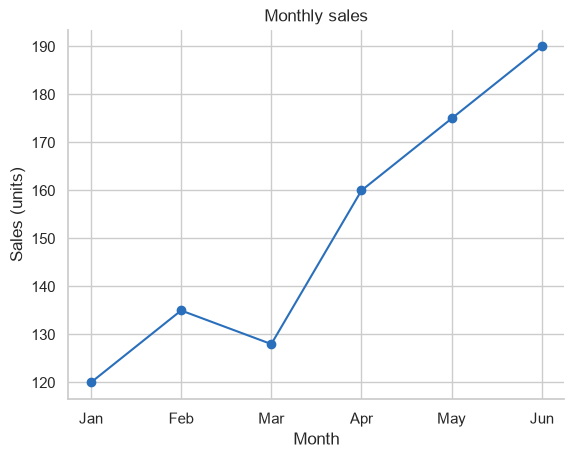

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales  = [120, 135, 128, 160, 175, 190]

plt.plot(months, sales, marker="o", color="#2a6fbb")
plt.title("Monthly sales")
plt.xlabel("Month")
plt.ylabel("Sales (units)")
plt.show()

## 2.2 Bar chart - compare categories

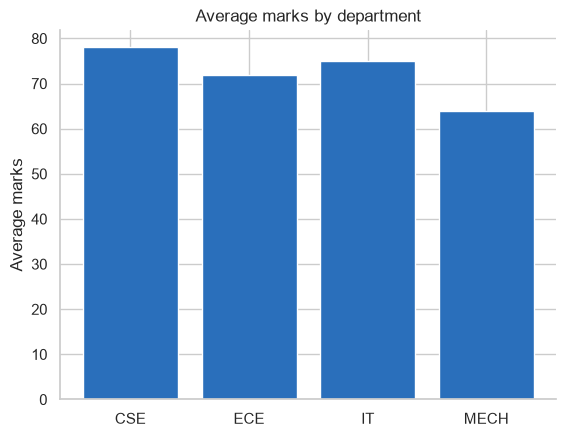

In [3]:
dept  = ["CSE", "ECE", "IT", "MECH"]
marks = [78, 72, 75, 64]

plt.bar(dept, marks, color="#2a6fbb")
plt.title("Average marks by department")
plt.ylabel("Average marks")
plt.show()

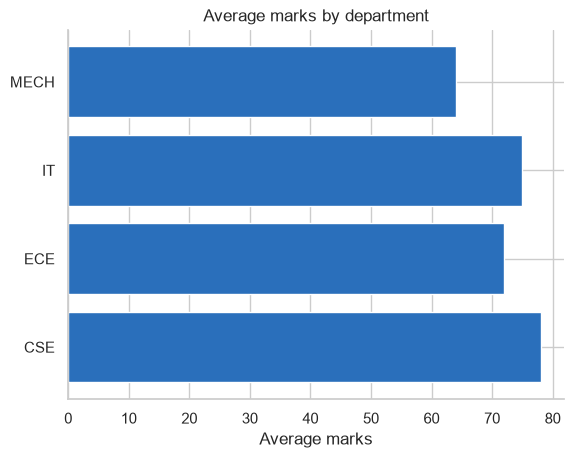

In [4]:
# horizontal bars are easier to read when labels are long
plt.barh(dept, marks, color="#2a6fbb")
plt.title("Average marks by department")
plt.xlabel("Average marks")
plt.show()

## 2.3 Scatter plot - relationship between two numbers

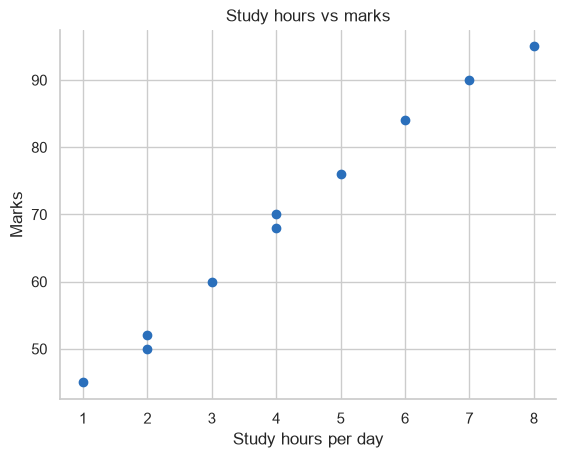

In [5]:
study_hours = [1, 2, 2, 3, 4, 4, 5, 6, 7, 8]
marks_s     = [45, 52, 50, 60, 68, 70, 76, 84, 90, 95]

plt.scatter(study_hours, marks_s, color="#2a6fbb")
plt.title("Study hours vs marks")
plt.xlabel("Study hours per day")
plt.ylabel("Marks")
plt.show()

## 2.4 Histogram - distribution of one number

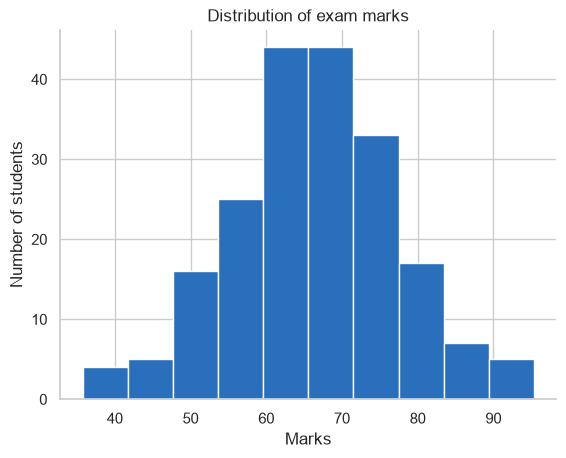

In [6]:
np.random.seed(1)
exam_marks = np.random.normal(loc=65, scale=12, size=200)

plt.hist(exam_marks, bins=10, color="#2a6fbb", edgecolor="white")
plt.title("Distribution of exam marks")
plt.xlabel("Marks")
plt.ylabel("Number of students")
plt.show()

## 2.5 Pie chart - only for a few parts of a whole

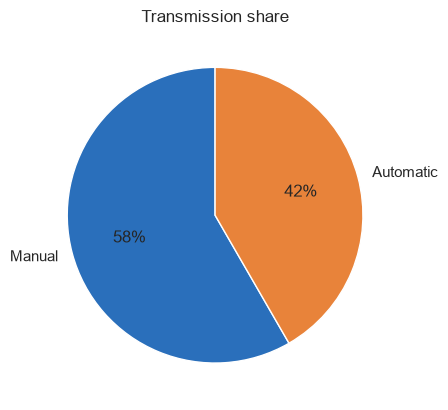

In [7]:
labels = ["Manual", "Automatic"]
counts = [7, 5]

plt.pie(counts, labels=labels, autopct="%1.0f%%", colors=["#2a6fbb", "#e8833a"], startangle=90)
plt.title("Transmission share")
plt.show()

## 2.6 Several charts in one figure - `subplots`

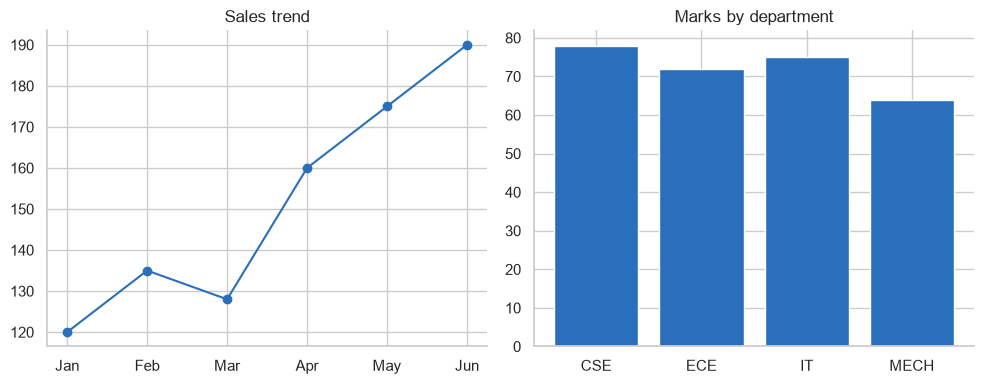

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(months, sales, marker="o", color="#2a6fbb")
axes[0].set_title("Sales trend")

axes[1].bar(dept, marks, color="#2a6fbb")
axes[1].set_title("Marks by department")

plt.tight_layout()
plt.show()

## 2.7 Compare two lines + legend + save

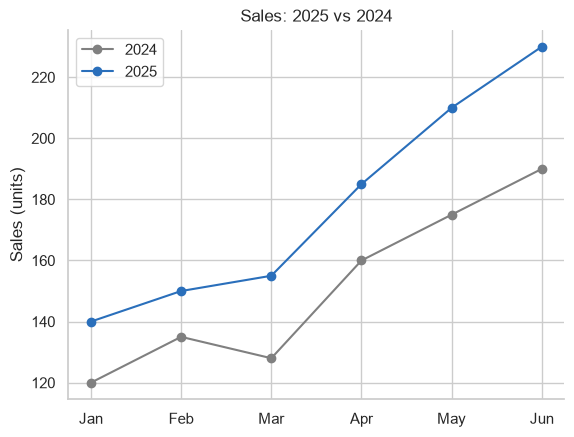

In [9]:
sales_2024 = [120, 135, 128, 160, 175, 190]
sales_2025 = [140, 150, 155, 185, 210, 230]

plt.plot(months, sales_2024, marker="o", color="gray", label="2024")
plt.plot(months, sales_2025, marker="o", color="#2a6fbb", label="2025")
plt.title("Sales: 2025 vs 2024")
plt.ylabel("Sales (units)")
plt.legend()
plt.savefig("sales_chart.png", dpi=150, bbox_inches="tight")   # save as image
plt.show()

### Try it yourself
Draw a line chart of daily temperature for 7 days. Give it a title and axis labels.

In [10]:
# your code here

# 3. Seaborn
Seaborn works directly with a DataFrame and does the grouping and colouring for you.

In [11]:
np.random.seed(0)
n = 80
students = pd.DataFrame({
    "dept":        np.random.choice(["CSE", "ECE", "IT", "MECH"], n),
    "gender":      np.random.choice(["M", "F"], n),
    "study_hours": np.random.uniform(1, 8, n).round(1),
})
students["marks"]      = (40 + 6 * students["study_hours"] + np.random.normal(0, 6, n)).round().clip(0, 100)
students["attendance"] = (60 + 3 * students["study_hours"] + np.random.normal(0, 5, n)).round().clip(0, 100)
students.head()

,dept,gender,study_hours,marks,attendance
0,CSE,M,3.2,57.0,69.0
1,MECH,F,3.9,74.0,68.0
2,ECE,M,1.4,52.0,66.0
3,CSE,F,5.8,77.0,77.0
4,MECH,F,5.0,65.0,80.0


## 3.1 Count of each category - `countplot`

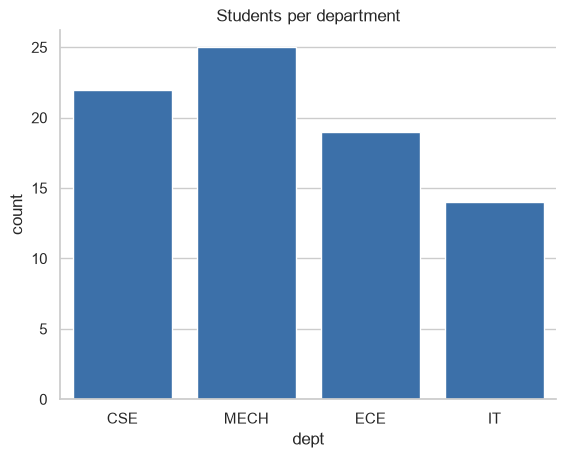

In [12]:
sns.countplot(data=students, x="dept", color="#2a6fbb")
plt.title("Students per department")
plt.show()

## 3.2 Average per category - `barplot`

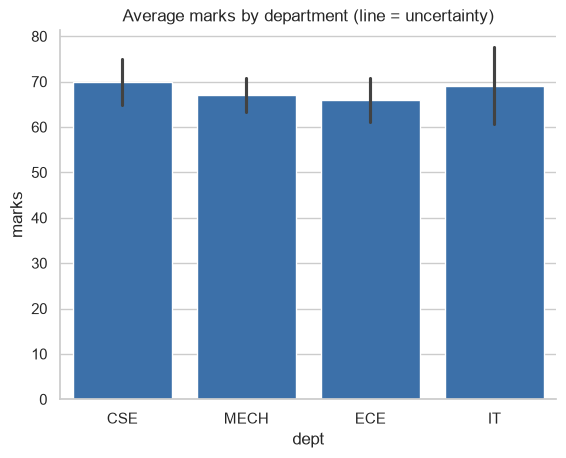

In [13]:
sns.barplot(data=students, x="dept", y="marks", color="#2a6fbb")
plt.title("Average marks by department (line = uncertainty)")
plt.show()

## 3.3 Distribution - `histplot`

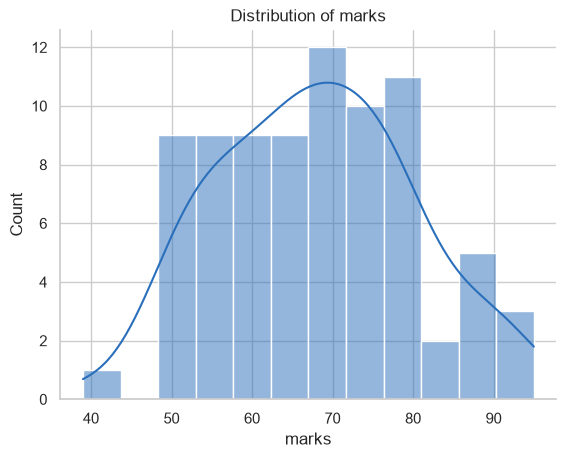

In [14]:
sns.histplot(data=students, x="marks", bins=12, kde=True, color="#2a6fbb")
plt.title("Distribution of marks")
plt.show()

## 3.4 Compare distributions - `boxplot`

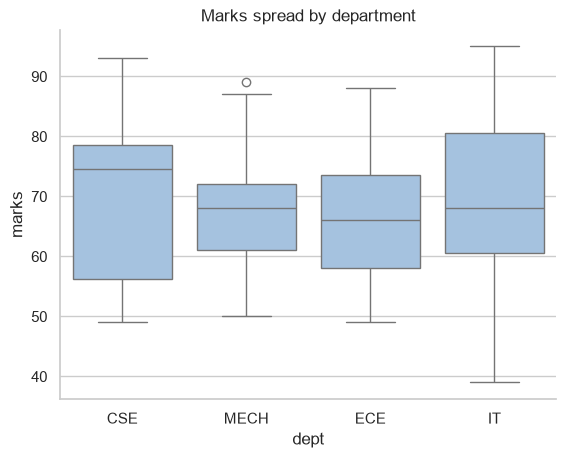

In [15]:
sns.boxplot(data=students, x="dept", y="marks", color="#9cc2e8")
plt.title("Marks spread by department")
plt.show()

## 3.5 Relationship + a third variable - `scatterplot` with `hue`

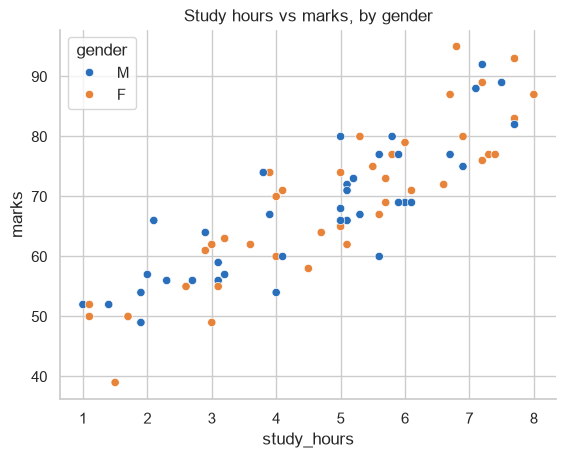

In [16]:
sns.scatterplot(data=students, x="study_hours", y="marks", hue="gender", palette=["#2a6fbb", "#e8833a"])
plt.title("Study hours vs marks, by gender")
plt.show()

Add a trend line with `regplot`:

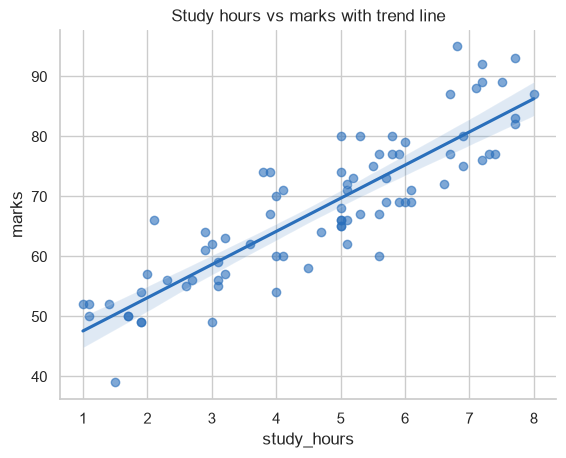

In [17]:
sns.regplot(data=students, x="study_hours", y="marks", color="#2a6fbb", scatter_kws={"alpha": 0.6})
plt.title("Study hours vs marks with trend line")
plt.show()

## 3.6 Correlation heatmap - many numbers at once

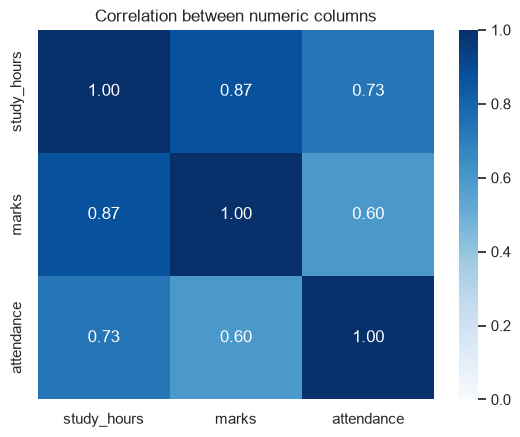

In [18]:
corr = students[["study_hours", "marks", "attendance"]].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

## 3.7 Everything vs everything - `pairplot`

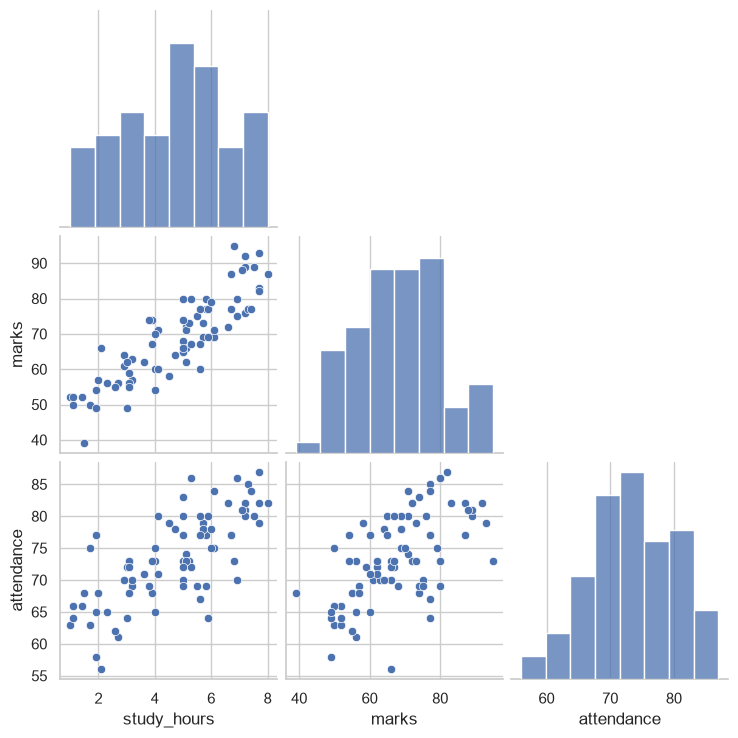

In [19]:
sns.pairplot(students[["study_hours", "marks", "attendance"]], corner=True)
plt.show()

### Try it yourself
Make a boxplot of `attendance` by `gender`. Which group is higher?

In [20]:
# your code here

# 4. Creating Effective Charts - Best Practices

1. **One chart = one message.** Decide what you want the viewer to notice.
2. **Pick the right chart** (see the table at the top).
3. **Always label** - title, axis labels with units, legend if more than one series.
4. **Start bars at zero.** Bars encode length, so a cut axis lies.
5. **Few colours, used with purpose.** Highlight what matters, grey the rest.
6. **Remove clutter** - heavy grids, 3D effects, borders, rainbow colours.
7. **Avoid pie charts with many slices**; sort bars so they are easy to compare.
8. **Never use two y-axes** in one chart; make two charts.
9. **Make it readable** - big enough fonts, colour-blind friendly colours.

## Bad vs good: the truncated axis

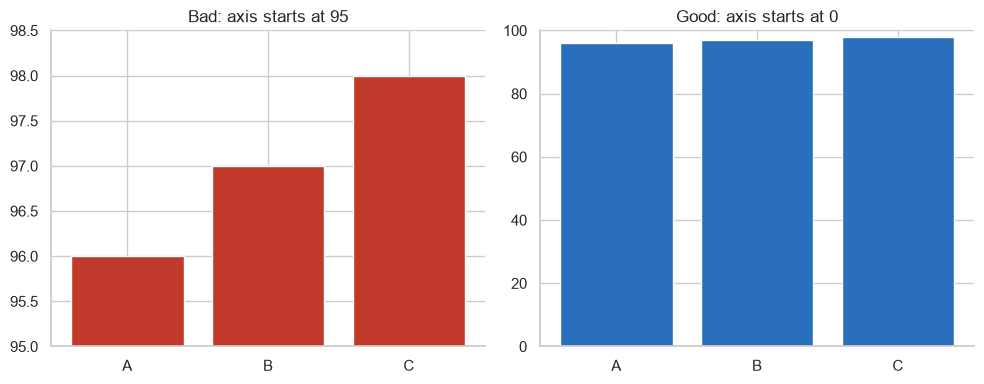

In [21]:
team   = ["A", "B", "C"]
scores = [96, 97, 98]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(team, scores, color="#c0392b")
axes[0].set_ylim(95, 98.5)                      # cut axis - exaggerates the gap
axes[0].set_title("Bad: axis starts at 95")

axes[1].bar(team, scores, color="#2a6fbb")
axes[1].set_ylim(0, 100)                        # honest axis
axes[1].set_title("Good: axis starts at 0")

plt.tight_layout()
plt.show()

The three teams look completely different on the left, but they are almost equal (96, 97, 98).

## Bad vs good: too many pie slices

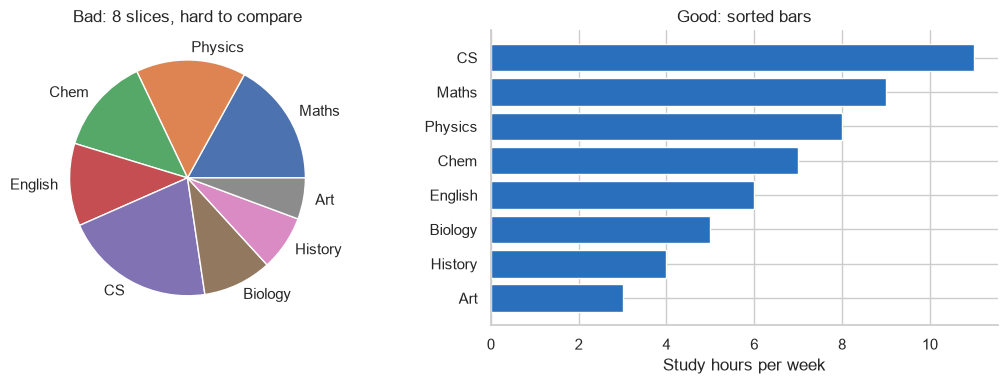

In [22]:
subjects = ["Maths", "Physics", "Chem", "English", "CS", "Biology", "History", "Art"]
hours    = [9, 8, 7, 6, 11, 5, 4, 3]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].pie(hours, labels=subjects)
axes[0].set_title("Bad: 8 slices, hard to compare")

order = np.argsort(hours)                       # sort smallest -> largest
axes[1].barh(np.array(subjects)[order], np.array(hours)[order], color="#2a6fbb")
axes[1].set_title("Good: sorted bars")
axes[1].set_xlabel("Study hours per week")

plt.tight_layout()
plt.show()

## Bad vs good: colour with purpose

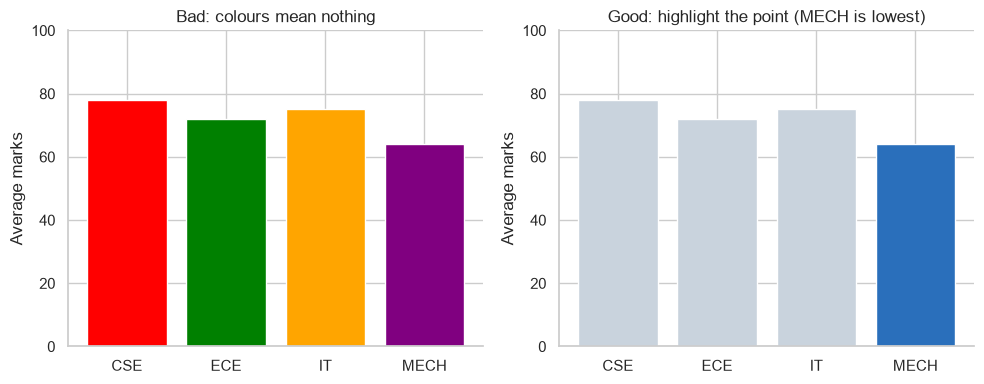

In [23]:
dept  = ["CSE", "ECE", "IT", "MECH"]
marks = [78, 72, 75, 64]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(dept, marks, color=["red", "green", "orange", "purple"])
axes[0].set_title("Bad: colours mean nothing")

colors = ["#c9d3dd", "#c9d3dd", "#c9d3dd", "#2a6fbb"]    # grey + one highlight
axes[1].bar(dept, marks, color=colors)
axes[1].set_title("Good: highlight the point (MECH is lowest)")

for ax in axes:
    ax.set_ylim(0, 100)
    ax.set_ylabel("Average marks")

plt.tight_layout()
plt.show()

# 5. Storytelling with Data
A chart answers a question; a **story** tells the viewer what to *do* about it.

**Structure:** Context → The finding → What to do.

| Weak chart | Story chart |
|---|---|
| Title: "Sales by month" | Title: **"Sales dipped in March, then grew 48% by June"** |
| All lines same colour | The important line in colour, others grey |
| Reader hunts for the point | An annotation points at it |

### Example: a college placement story

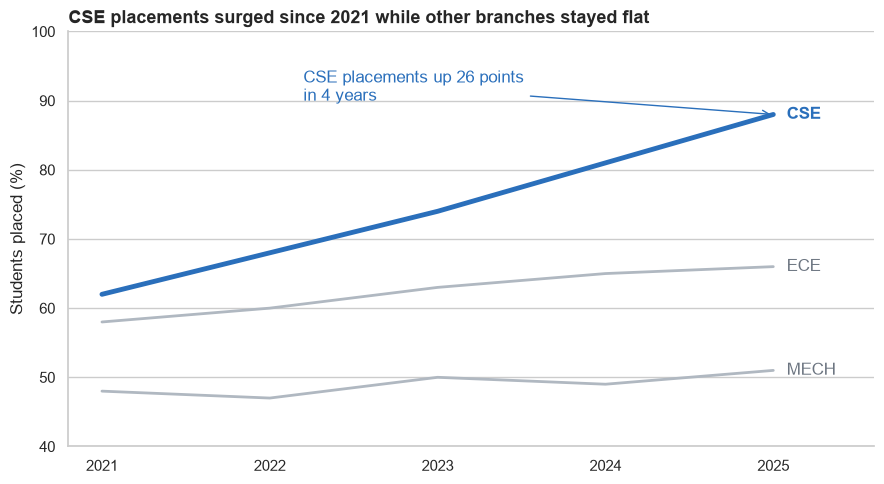

In [24]:
years = [2021, 2022, 2023, 2024, 2025]
cse   = [62, 68, 74, 81, 88]
ece   = [58, 60, 63, 65, 66]
mech  = [48, 47, 50, 49, 51]

fig, ax = plt.subplots(figsize=(9, 5))

# grey for context, blue for the hero
ax.plot(years, ece,  color="#b0b8c1", linewidth=2)
ax.plot(years, mech, color="#b0b8c1", linewidth=2)
ax.plot(years, cse,  color="#2a6fbb", linewidth=3.5)

# label lines directly instead of using a legend
ax.text(2025.08, 88, "CSE",  color="#2a6fbb", fontweight="bold", va="center")
ax.text(2025.08, 66, "ECE",  color="#6b7480", va="center")
ax.text(2025.08, 51, "MECH", color="#6b7480", va="center")

# annotate the key insight
ax.annotate("CSE placements up 26 points\nin 4 years",
            xy=(2025, 88), xytext=(2022.2, 90),
            arrowprops=dict(arrowstyle="->", color="#2a6fbb"), color="#2a6fbb")

ax.set_title("CSE placements surged since 2021 while other branches stayed flat",
             loc="left", fontsize=13, fontweight="bold")
ax.set_ylabel("Students placed (%)")
ax.set_xticks(years)
ax.set_ylim(40, 100)
ax.set_xlim(2020.8, 2025.6)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

**What made it a story?**
1. The title states the finding, not just the topic.
2. One colour for the hero, grey for the rest.
3. Direct labels - no legend to look up.
4. One annotation points at the key number.
5. Nothing else: no extra colours, no clutter.

**Chart checklist before you present**
- [ ] Does the title say the message?
- [ ] Are axes labelled with units?
- [ ] Do bars start at zero?
- [ ] Is colour used only to highlight?
- [ ] Can someone understand it in 5 seconds?

### Try it yourself
Take the department marks bar chart (CSE 78, ECE 72, IT 75, MECH 64). Make a "story" version: write a message title, grey all bars except one, and add an annotation.

In [25]:
# your code here